# پروژه پایانی درس مباحث ویژه

## رگرسیون خطی چند متغیره با Mini-Batch Gradient Descent

پیاده‌سازی روی California Housing Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

## ۱. آماده سازی داده

In [2]:
housing = fetch_california_housing()

X = housing.data
y = housing.target
feature_names = housing.feature_names

df = pd.DataFrame(X, columns=feature_names)
df["Price"] = y

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print("Shape:", df.shape)
print()
print(df.isnull().sum())

Shape: (20640, 9)

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Price         0
dtype: int64


In [4]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


## ۲. تقسیم داده و استانداردسازی


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = np.c_[np.ones(X_train.shape[0]), X_train]
X_test = np.c_[np.ones(X_test.shape[0]), X_test]

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (16512, 9)
Test shape: (4128, 9)


## ۳. پیاده سازی مدل از صفر

In [6]:
def predict(X, weights):
    """
    پیش‌بینی قیمت با رگرسیون خطی چندمتغیره
    """

    n_samples = X.shape[0]
    n_features = X.shape[1]

    y_pred = np.zeros(n_samples)

    for i in range(n_samples):

        prediction = 0

        for j in range(n_features):
            prediction += X[i, j] * weights[j]

        y_pred[i] = prediction

    return y_pred


def compute_cost(y_true, y_pred):
    """
    محاسبه تابع هزینه MSE تقسیم بر 2
    """

    n_samples = len(y_true)
    total_error = 0

    for i in range(n_samples):

        error = y_pred[i] - y_true[i]

        total_error += error ** 2

    cost = total_error / (2 * n_samples)

    return cost


def compute_gradient(X, y, weights):
    """
    محاسبه گرادیان تمام وزن‌های مدل
    """

    n_samples = X.shape[0]
    n_features = X.shape[1]

    y_pred = predict(X, weights)

    gradients = np.zeros(n_features)

    for j in range(n_features):

        gradient_sum = 0

        for i in range(n_samples):

            error = y_pred[i] - y[i]

            gradient_sum += error * X[i, j]

        gradients[j] = gradient_sum / n_samples

    return gradients

In [7]:
def mini_batch_gd(
    X,
    y,
    lr=0.01,
    epochs=100,
    batch_size=32
):
    """
    آموزش رگرسیون خطی چندمتغیره با
    Mini-Batch Gradient Descent
    """

    n_samples = X.shape[0]
    n_features = X.shape[1]

    weights = np.zeros(n_features)

    loss_history = []

    for epoch in range(epochs):

        indices = np.random.permutation(n_samples)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for start in range(0, n_samples, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            gradients = compute_gradient(
                X_batch,
                y_batch,
                weights
            )

            for j in range(n_features):

                weights[j] = (
                    weights[j]
                    - lr * gradients[j]
                )

        train_prediction = predict(X, weights)

        loss = compute_cost(
            y,
            train_prediction
        )

        loss_history.append(loss)

    return weights, loss_history

### توابع ارزیابی (MAE, MSE, R2)

In [8]:
def calc_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def calc_mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def calc_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

## ۴. آموزش مدل

In [9]:
weights, loss_history = mini_batch_gd(
    X_train, y_train,
    lr=0.01,
    epochs=100,
    batch_size=32
)

In [10]:
y_pred = predict(X_test, weights)

mae = calc_mae(y_test, y_pred)
mse = calc_mse(y_test, y_pred)
r2 = calc_r2(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("R2:", r2)

MAE: 0.5353980046398963
MSE: 0.5500333677437128
R2: 0.5802582423679051


In [11]:
compare_df = pd.DataFrame({
    "Real Price": y_test[:10],
    "Predicted Price": y_pred[:10]
})
compare_df

,Real Price,Predicted Price
0,0.47700,0.731939
1,0.45800,1.746341
2,5.00001,2.678758
3,2.18600,2.832539
4,2.78000,2.587150
5,1.58700,2.012713
6,1.98200,2.622068
7,1.57500,2.168595
8,3.40000,2.738744
9,4.46600,3.883888


## ۵. نمودارها


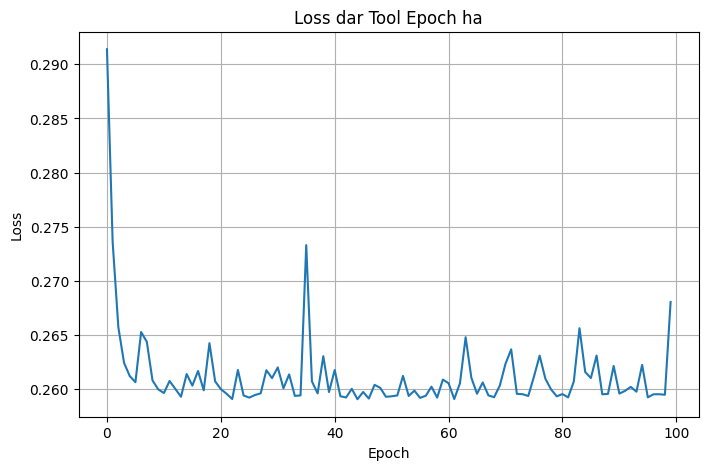

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss dar Tool Epoch ha")
plt.grid()
plt.show()

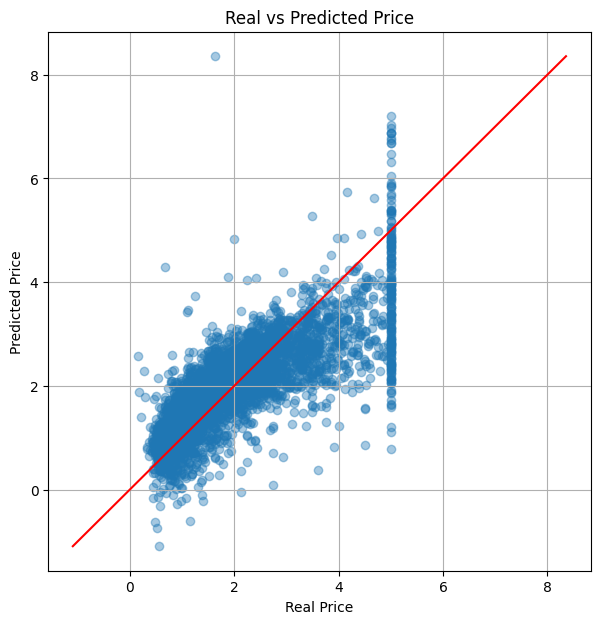

In [13]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.4)

mn = min(y_test.min(), y_pred.min())
mx = max(y_test.max(), y_pred.max())
plt.plot([mn, mx], [mn, mx], color="red")

plt.xlabel("Real Price")
plt.ylabel("Predicted Price")
plt.title("Real vs Predicted Price")
plt.grid()
plt.show()

In [14]:
coef_df = pd.DataFrame({
    "Feature": ["Bias"] + feature_names,
    "Coefficient": weights
})

In [15]:
coef_df

feature_coef_df = coef_df[
    coef_df["Feature"] != "Bias"
]

most_positive = feature_coef_df.loc[
    feature_coef_df["Coefficient"].idxmax()
]

most_negative = feature_coef_df.loc[
    feature_coef_df["Coefficient"].idxmin()
]

print(
    "Most positive feature:",
    most_positive["Feature"]
)

print(
    "Most negative feature:",
    most_negative["Feature"]
    )

Most positive feature: MedInc
Most negative feature: Latitude


In [16]:
house_age_coef = feature_coef_df.loc[
    feature_coef_df["Feature"] == "HouseAge",
    "Coefficient"
].iloc[0]

if house_age_coef < 0:
    print("HouseAge has a negative effect.")
else:
    print("HouseAge does not have a negative effect.")

HouseAge does not have a negative effect.


## ۶. آزمایش با مقادیر مختلف

### ۶.۱ اندازه mini-batch


In [17]:
for bs in [8, 16, 32]:
    np.random.seed(42)

    w, lh = mini_batch_gd(
        X_train,
        y_train,
        lr=0.005,
        epochs=50,
        batch_size=bs
    )

    print(
        f"batch_size={bs} -> "
        f"final loss={lh[-1]:.5f}"
    )

batch_size=8 -> final loss=0.25938
batch_size=16 -> final loss=0.25932
batch_size=32 -> final loss=0.25917


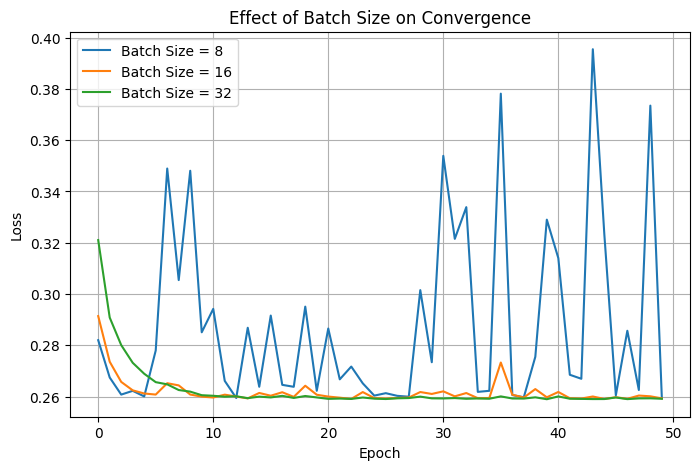

In [18]:
plt.figure(figsize=(8, 5))

for bs in [8, 16, 32]:
    np.random.seed(42)

    w, lh = mini_batch_gd(
        X_train,
        y_train,
        lr=0.005,
        epochs=50,
        batch_size=bs
    )

    plt.plot(lh, label=f"Batch Size = {bs}")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Effect of Batch Size on Convergence")
plt.legend()
plt.grid()
plt.show()

### ۶.۲ نرخ یادگیری (learning rate)


In [19]:
for lr in [0.001, 0.005, 0.01, 0.05, 0.1]:
    np.random.seed(42)

    w, lh = mini_batch_gd(
        X_train,
        y_train,
        lr=lr,
        epochs=50,
        batch_size=32
    )

    final_loss = lh[-1]

    if not np.isfinite(final_loss) or final_loss > 1000:
        print(f"lr={lr} -> Diverged")
    else:
        print(
            f"lr={lr} -> "
            f"final loss={final_loss:.5f}"
        )

lr=0.001 -> final loss=0.26045
lr=0.005 -> final loss=0.25917
lr=0.01 -> final loss=0.25932
lr=0.05 -> Diverged
lr=0.1 -> Diverged


### ۶.۳ تعداد epoch


In [20]:
for ep in [20, 50, 100, 200]:
    np.random.seed(42)
    w, lh = mini_batch_gd(X_train, y_train, lr=0.01, epochs=ep, batch_size=32)
    print(f"epochs={ep}  ->  final loss = {lh[-1]:.5f}")

epochs=20  ->  final loss = 0.26074
epochs=50  ->  final loss = 0.25932
epochs=100  ->  final loss = 0.26806
epochs=200  ->  final loss = 0.26062


## ۷. تحلیل خطا روی خانه‌های ارزان و گران


In [25]:
errors = np.abs(y_test - y_pred)

top10 = np.percentile(y_test, 90)
bottom10 = np.percentile(y_test, 10)

expensive_error = errors[y_test >= top10].mean()
cheap_error = errors[y_test <= bottom10].mean()

print("miangin khataye kolli:", errors.mean())
print("miangin khataye khoonehaye gerun (10% bala):", errors[y_test >= top10].mean())
print("miangin khataye khoonehaye arzoon (10% paeen):", errors[y_test <= bottom10].mean())

miangin khataye kolli: 0.5353980046398963
miangin khataye khoonehaye gerun (10% bala): 1.346463487079037
miangin khataye khoonehaye arzoon (10% paeen): 0.41867288458464735


In [26]:
if expensive_error > cheap_error:
    print(
        "The model has a larger error "
        "for expensive houses."
    )
else:
    print(
        "The model has a larger error "
        "for cheap houses."
    )

The model has a larger error for expensive houses.
